##KHỞI TẠO ẢNH NHỊ PHÂN

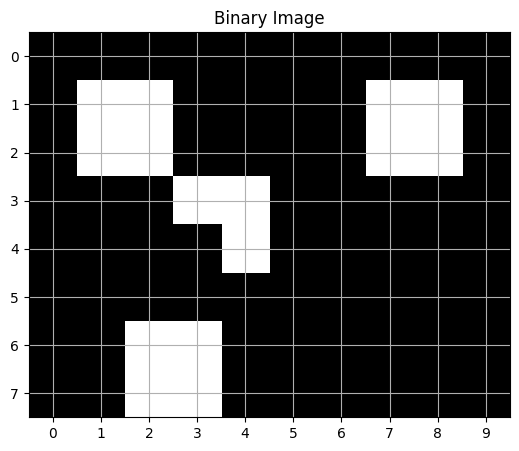

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

binary = np.zeros((8, 10), dtype=np.uint8)

pixels = [
    (1,1), (1,2), (2,1), (2,2),
    (3,3), (3,4), (4,4),
    (1,7), (1,8), (2,7), (2,8),
    (6,2), (6,3), (7,2), (7,3)
]

for y, x in pixels:
    binary[y, x] = 255
#Hiển thị
plt.figure(figsize=(8, 5))
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Image")
plt.xticks(range(10))
plt.yticks(range(8))
plt.grid()
plt.show()

##PHÂN CỤM VÀ GÁN ID CHO TỪNG VÙNG TRẮNG

In [34]:
for connectivity in [4, 8]: #4 là 4 pixel (trên dưới trái phải) quanh pixel chọn, 8 pixel (chéo trên dưới phải, chéo trên dưới trái) xung quanh pixel được chọn

    num_labels, labels = cv2.connectedComponents(
        binary,
        connectivity=connectivity
    )

    print(f"\nConnectivity = {connectivity}")
    print(f"So vung doi tuong: {num_labels - 1}")#Tổng số nhãn, bao gồm nền
    print("Label Matrix:")
    print(labels)#Ma trận ghi rõ mỗi pixel thuộc cụm nào



Connectivity = 4
So vung doi tuong: 4
Label Matrix:
[[0 0 0 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 2 2 0]
 [0 1 1 0 0 0 0 2 2 0]
 [0 0 0 3 3 0 0 0 0 0]
 [0 0 0 0 3 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 4 4 0 0 0 0 0 0]
 [0 0 4 4 0 0 0 0 0 0]]

Connectivity = 8
So vung doi tuong: 3
Label Matrix:
[[0 0 0 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 2 2 0]
 [0 1 1 0 0 0 0 2 2 0]
 [0 0 0 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 3 3 0 0 0 0 0 0]
 [0 0 3 3 0 0 0 0 0 0]]


###CONECT 4 cho ra 4 cụm
###CONECT 8 cho ra 3 cụm

Khảo sát sau khi dán nhãn

### 3. Phát hiện vùng liên thông bằng OpenCV

**Mục đích:** Sử dụng `cv2.connectedComponents()` để tìm kiếm và gán ID cho các vùng pixel trắng liên thông trong ảnh nhị phân.

Thực nghiệm hai chế độ:
- Connectivity 4: Xét liên kết theo bốn hướng trên, dưới, trái, phải.
- Connectivity 8: Xét thêm bốn hướng đường chéo.

Kết quả trả về gồm tổng số nhãn và ma trận nhãn (Label Matrix). Nhãn 0 được dành cho nền.

**Liên hệ Project:** Đây là thuật toán cốt lõi của Thành viên 2. Khi tích hợp GUI, người dùng có thể thay đổi Connectivity để quan sát sự khác biệt về số vùng phát hiện được. Kết quả gán nhãn sẽ được chuyển cho Thành viên 3 để thống kê và đếm sản phẩm hợp lệ.

In [35]:
num_labels, labels = cv2.connectedComponents(
    binary,
    connectivity=8#dùng connect 8
)

print("Kích thước ảnh:", binary.shape)#kích thước ảnh vào
print("Kích thước ma trận nhãn:", labels.shape)#kích thước ma trận nhãn
print("Kiểu dữ liệu nhãn:", labels.dtype)

print("Tổng số nhãn:", num_labels)
print("Số vùng đối tượng:", num_labels - 1)

print("Các ID xuất hiện:", np.unique(labels))#chuyển thành ma trận số chưa ID
print("\nMa trận nhãn:")
print(labels)

Kích thước ảnh: (8, 10)
Kích thước ma trận nhãn: (8, 10)
Kiểu dữ liệu nhãn: int32
Tổng số nhãn: 4
Số vùng đối tượng: 3
Các ID xuất hiện: [0 1 2 3]

Ma trận nhãn:
[[0 0 0 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 2 2 0]
 [0 1 1 0 0 0 0 2 2 0]
 [0 0 0 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 3 3 0 0 0 0 0 0]
 [0 0 3 3 0 0 0 0 0 0]]


### 4. Phân tích kết quả gán nhãn (Label Matrix)

**Mục đích:** Kiểm tra cấu trúc và dữ liệu trả về của thuật toán Connected Components, bao gồm kích thước ma trận, kiểu dữ liệu, tổng số nhãn và ID của từng vùng.

Sau khi gán nhãn:
- Nền mang ID 0.
- Các vùng liên thông được gán ID 1, 2, 3,...
- Những pixel thuộc cùng một vùng có cùng ID.

**Liên hệ Project:** Label Matrix là dữ liệu trung gian quan trọng giữa Thành viên 2 và Thành viên 3. Dựa vào các ID, module thống kê có thể xác định những pixel thuộc cùng một sản phẩm, tính diện tích, tọa độ tâm và Bounding Box.

Ở bước này, số vùng liên thông chỉ là kết quả phát hiện ban đầu, chưa phải số lượng sản phẩm hợp lệ cuối cùng.

###HÀM TÔ MÀU

In [36]:
def colorize_labels(labels, seed=42):

    num_colors = int(labels.max()) + 1#định số màu cần tạo

    rng = np.random.default_rng(seed)#sinh màu để tô

    colors = rng.integers(
        50, 256,
        size=(num_colors, 3),
        dtype=np.uint8
    )#tạo bảng màu, gồm 3 giá trị RGB

    colors[0] = [0, 0, 0]#màu nền đặt thành màu đen

    colored_image = colors[labels]#gán màu tưởng đương ID

    return colored_image

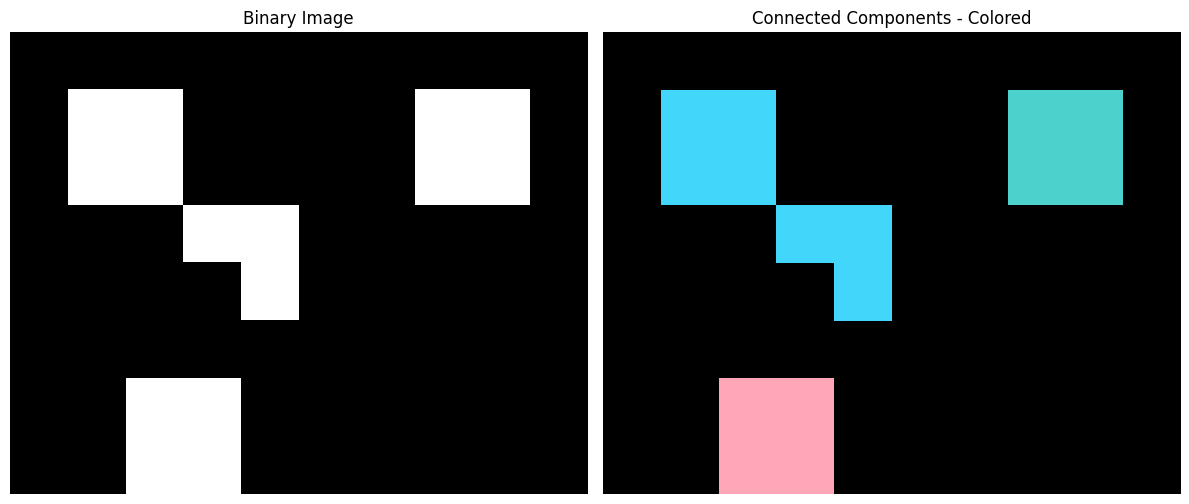

In [37]:
colored_image = colorize_labels(labels)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(colored_image)
plt.title("Connected Components - Colored")
plt.axis("off")

plt.tight_layout()
plt.show()


### 5. Xây dựng hàm tô màu các vùng liên thông

**Mục đích:** Chuyển ma trận nhãn thành ảnh RGB, trong đó mỗi vùng liên thông được biểu diễn bằng một màu riêng biệt.

Hàm sử dụng ID của từng vùng để tra bảng màu. Các pixel có cùng ID sẽ nhận cùng một màu, còn vùng nền được giữ màu đen.

**Liên hệ Project:** Việc tô màu giúp người dùng dễ dàng phân biệt các sản phẩm đã được thuật toán phát hiện, thay vì chỉ quan sát ma trận gồm các con số.

Trong GUI, ảnh tô màu sẽ giúp kiểm tra trực quan:
- Sản phẩm nào đã được nhận diện thành một vùng riêng.
- Hai sản phẩm có bị gộp thành một vùng hay không.
- Một sản phẩm có bị chia thành nhiều vùng hay không.

Tô màu chỉ phục vụ hiển thị, không làm thay đổi kết quả gán nhãn hoặc số lượng sản phẩm.

##DÙNG cv2.applyColorMap

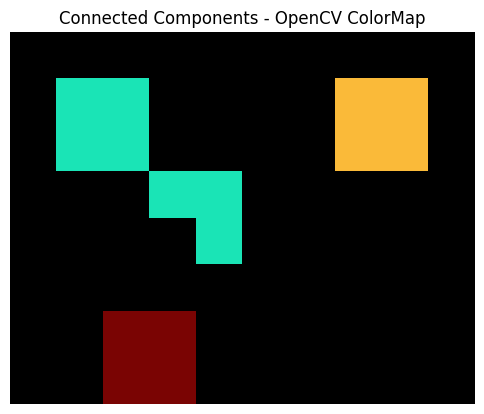

In [38]:
labels_8bit = cv2.normalize(
    labels,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

colored_cv = cv2.applyColorMap(
    labels_8bit,
    cv2.COLORMAP_TURBO
)

colored_cv[labels == 0] = [0, 0, 0]

colored_cv_rgb = cv2.cvtColor(
    colored_cv,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(6, 5))
plt.imshow(colored_cv_rgb)
plt.title("Connected Components - OpenCV ColorMap")
plt.axis("off")
plt.show()


### 7. Trực quan hóa vùng liên thông bằng OpenCV ColorMap

**Mục đích:** Sử dụng `cv2.applyColorMap()` để biểu diễn ma trận nhãn dưới dạng ảnh màu thông qua bảng màu có sẵn của OpenCV.

Khác với phương pháp tạo bảng màu ngẫu nhiên ở Cell 5, phương pháp này ánh xạ giá trị nhãn đã chuyển về 8-bit sang các màu trong bảng màu TURBO.

**Liên hệ Project:** Đây là phương án trực quan hóa bổ sung để so sánh các cách hiển thị kết quả Connected Components.

Trong GUI, có thể lựa chọn một phương pháp tô màu phù hợp để người dùng dễ quan sát các vùng đã phát hiện.

**Lưu ý:** ColorMap không thực hiện phân vùng hoặc đếm sản phẩm. Khi số ID lớn, việc chuyển về 8-bit có thể khiến nhiều vùng nhận cùng màu. Vì vậy, hệ thống vẫn phải sử dụng Label Matrix gốc để thống kê.

### 8. Đánh giá ảnh hưởng của Connectivity đến kết quả phân vùng

**Mục đích:** So sánh kết quả Connected Components khi sử dụng Connectivity 4 và Connectivity 8 trên cùng một ảnh nhị phân.

Connectivity 4 chỉ xét các pixel kề theo chiều ngang và dọc, trong khi Connectivity 8 xét thêm các pixel kề theo đường chéo.

Do đó, hai chế độ có thể tạo ra số lượng vùng liên thông khác nhau, đặc biệt khi các vùng pixel chỉ tiếp xúc tại góc.

**Liên hệ Project:** Connectivity là một tham số quan trọng trên GUI, cho phép người dùng thay đổi cách xác định các vùng liên thông.

Việc lựa chọn Connectivity có thể ảnh hưởng trực tiếp đến kết quả đếm:
- Connectivity 4 có thể chia một sản phẩm có liên kết chéo thành nhiều vùng.
- Connectivity 8 có thể gộp các sản phẩm tiếp xúc ở góc thành cùng một vùng.

Thực nghiệm này giúp đánh giá ảnh hưởng của Connectivity, từ đó lựa chọn cấu hình phù hợp với đặc điểm bộ dữ liệu thử nghiệm của nhóm.

###Tự Cài đặt Connected Components bằng BFS (không dùng sẵn)

In [39]:
import numpy as np
from collections import deque

def connected_components_scratch(binary, connectivity=8):

    # 1. Kiểm tra tham số Connectivity
    if connectivity not in (4, 8):
        raise ValueError("Connectivity phải là 4 hoặc 8")

    # 2. Lấy kích thước ảnh
    if binary.ndim != 2:
        raise ValueError("Ảnh đầu vào phải là ma trận 2D")

    h, w = binary.shape

    # 3. Tạo ma trận nhãn ban đầu
    labels = np.zeros((h, w), dtype=np.int32)#ma trận lưu ID cho pixel

    # 4. Khai báo các hướng hàng xóm
    neighbors = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1)
    ]

    if connectivity == 8:
        neighbors += [
            (-1, -1),
            (-1, 1),
            (1, -1),
            (1, 1)
        ]

    current_label = 0

    # 5. Duyệt từng pixel trong ảnh
    for y in range(h):
        for x in range(w):

            # Bỏ qua pixel nền hoặc đã gán nhãn
            if binary[y, x] == 0 or labels[y, x] != 0:
                continue

            # 6. Phát hiện vùng mới
            current_label += 1
            labels[y, x] = current_label

            queue = deque([(y, x)])

            # 7. BFS tìm toàn bộ pixel trong vùng
            while queue:

                cy, cx = queue.popleft()

                for dy, dx in neighbors:

                    ny = cy + dy
                    nx = cx + dx

                    # Kiểm tra vị trí hợp lệ
                    if 0 <= ny < h and 0 <= nx < w:

                        # Nếu pixel trắng và chưa được xét
                        if binary[ny, nx] != 0 and labels[ny, nx] == 0:

                            labels[ny, nx] = current_label
                            queue.append((ny, nx))

    # Trả về tổng nhãn (bao gồm nền) và ma trận nhãn
    return current_label + 1, labels

### 9. Xây dựng thuật toán Connected Components bằng Flood-fill BFS

**Mục đích:** Tự cài đặt thuật toán xác định các vùng liên thông trong ảnh nhị phân mà không sử dụng trực tiếp `cv2.connectedComponents()`.

Thuật toán thực hiện các bước:
1. Khởi tạo ma trận nhãn có cùng kích thước với ảnh đầu vào.
2. Duyệt lần lượt từng pixel của ảnh.
3. Khi gặp pixel trắng chưa được gán nhãn, tạo một ID mới.
4. Sử dụng BFS để tìm các pixel trắng liên thông và gán cùng ID.
5. Lặp lại cho đến khi toàn bộ ảnh được xử lý.

**Liên hệ Project:** Đây là thuật toán Scratch của Thành viên 2, giúp giải thích nguyên lý tìm và gán nhãn các sản phẩm trong ảnh. Hàm được xây dựng có đầu vào, đầu ra tương thích với OpenCV để phục vụ việc so sánh kết quả và hiệu năng.

Thuật toán hỗ trợ hai chế độ Connectivity 4 và Connectivity 8.

In [40]:
num_scratch, labels_scratch = connected_components_scratch(
    binary,
    connectivity=8
)

print("Số vùng liên thông:", num_scratch - 1)
print("\nMa trận nhãn Scratch:")
print(labels_scratch)

Số vùng liên thông: 3

Ma trận nhãn Scratch:
[[0 0 0 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 2 2 0]
 [0 1 1 0 0 0 0 2 2 0]
 [0 0 0 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 3 3 0 0 0 0 0 0]
 [0 0 3 3 0 0 0 0 0 0]]


### 10. Kiểm tra kết quả thuật toán Flood-fill BFS

**Mục đích:** Áp dụng thuật toán Scratch trên ảnh nhị phân đã tạo để kiểm tra khả năng phát hiện và gán nhãn các vùng liên thông.

Kết quả cần quan sát:
- Tổng số vùng liên thông phát hiện được.
- ID của từng vùng.
- Ma trận nhãn sau khi thuật toán hoàn thành.

**Liên hệ Project:** Kiểm tra thuật toán độc lập trước khi tích hợp với ảnh thực tế từ module Morphology. Đây là bước giúp phát hiện các lỗi trong quá trình duyệt pixel, xác định hàng xóm hoặc đánh nhãn.

In [41]:
binary_test = np.array([
    [255,   0],
    [  0, 255]
], dtype=np.uint8)

for connectivity in [4, 8]:

    num, result = connected_components_scratch(
        binary_test,
        connectivity=connectivity
    )

    print(f"\nConnectivity = {connectivity}")
    print("Số vùng:", num - 1)
    print(result)


Connectivity = 4
Số vùng: 2
[[1 0]
 [0 2]]

Connectivity = 8
Số vùng: 1
[[1 0]
 [0 1]]


### 11. Thử nghiệm Connectivity 4 và 8 trong thuật toán Scratch

**Mục đích:** Kiểm tra khả năng xác định các vùng liên thông theo hai chế độ kết nối khác nhau.

Sử dụng một ảnh nhị phân nhỏ có hai pixel trắng chỉ tiếp xúc theo đường chéo để làm rõ sự khác biệt giữa Connectivity 4 và 8.

**Liên hệ Project:** Kết quả thử nghiệm chứng minh thuật toán Scratch có thể xử lý tham số Connectivity do người dùng lựa chọn trên GUI.

Đồng thời, thí nghiệm giúp giải thích tại sao thay đổi Connectivity có thể làm thay đổi số vùng liên thông, từ đó ảnh hưởng đến kết quả đếm sản phẩm.

In [42]:
for connectivity in [4, 8]:

    num_cv, labels_cv = cv2.connectedComponents(
        binary,
        connectivity=connectivity
    )

    num_sc, labels_sc = connected_components_scratch(
        binary,
        connectivity=connectivity
    )

    print(f"\nConnectivity = {connectivity}")
    print("OpenCV:", num_cv - 1, "vùng")
    print("Scratch:", num_sc - 1, "vùng")
    print("Số vùng trùng khớp:", num_cv == num_sc)


Connectivity = 4
OpenCV: 4 vùng
Scratch: 4 vùng
Số vùng trùng khớp: True

Connectivity = 8
OpenCV: 3 vùng
Scratch: 3 vùng
Số vùng trùng khớp: True


### 12. Đối chiếu kết quả Connected Components giữa Scratch và OpenCV

**Mục đích:** Chạy hai thuật toán trên cùng ảnh nhị phân và cùng tham số Connectivity để kiểm tra tính nhất quán của số vùng được phát hiện.

- OpenCV: Sử dụng thuật toán Connected Components được thư viện cung cấp.
- Scratch: Sử dụng Flood-fill BFS tự xây dựng bằng Python.

**Liên hệ Project:** Đây là bước kiểm chứng ban đầu nhằm bảo đảm thuật toán tự viết thực hiện đúng chức năng gán nhãn trước khi đánh giá hiệu năng.

Lưu ý rằng số lượng vùng bằng nhau chưa đủ để chứng minh hai thuật toán gán nhãn hoàn toàn tương đương. Cần tiếp tục đối chiếu các vùng pixel trong bước thực nghiệm tiếp theo.

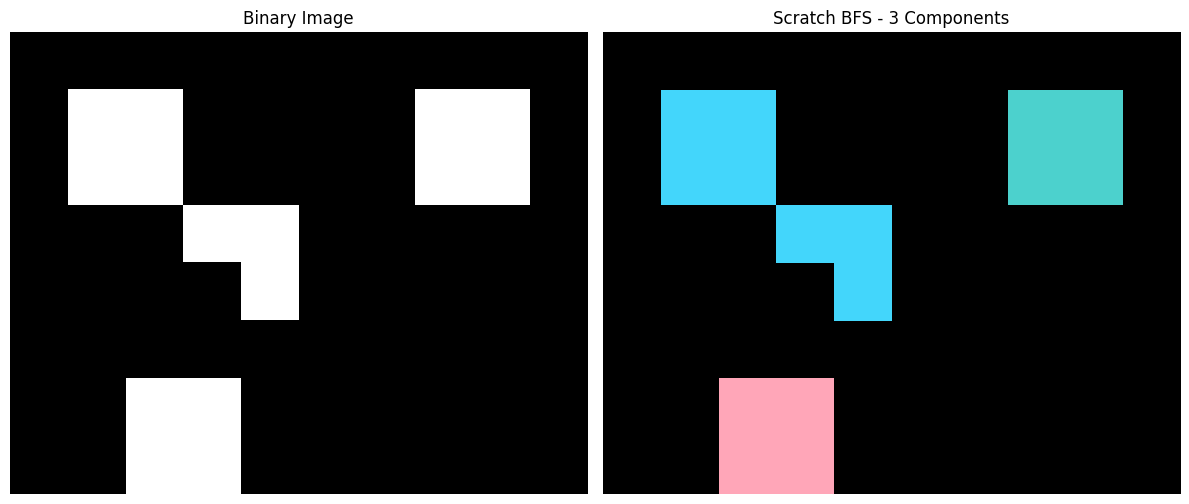

In [43]:
num_scratch, labels_scratch = connected_components_scratch(
    binary,
    connectivity=8
)

colored_scratch = colorize_labels(labels_scratch)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(colored_scratch)
plt.title(f"Scratch BFS - {num_scratch - 1} Components")
plt.axis("off")

plt.tight_layout()
plt.show()

### 13. Trực quan hóa kết quả của thuật toán Scratch

**Mục đích:** Sử dụng hàm tô màu đã xây dựng để hiển thị các vùng liên thông được phát hiện bởi thuật toán Flood-fill BFS.

Ảnh đầu vào được hiển thị cùng với ảnh gán nhãn màu nhằm quan sát trực tiếp kết quả phân vùng.

**Liên hệ Project:** Khi người dùng chọn chế độ Scratch trên GUI, hệ thống có thể gọi thuật toán BFS để tạo Label Matrix, sau đó sử dụng hàm tô màu để hiển thị kết quả.

Việc tách thuật toán gán nhãn và chức năng tô màu thành hai hàm riêng giúp GUI có thể sử dụng chung chức năng hiển thị cho cả OpenCV và Scratch.

### Tổng kết – Connected Components bằng Flood-fill BFS

Đã xây dựng thuật toán Connected Components bằng phương pháp Flood-fill BFS sử dụng vòng lặp Python.

Thuật toán thực hiện việc duyệt các pixel của ảnh nhị phân, phát hiện những vùng pixel trắng liên thông và gán ID riêng cho từng vùng.

**Kết quả đạt được:**
- Xây dựng hàm Connected Components không phụ thuộc vào hàm gán nhãn của OpenCV.
- Hỗ trợ Connectivity 4 và 8.
- Tạo ma trận nhãn cho các vùng liên thông.
- Trực quan hóa kết quả thông qua ảnh tô màu.
- Đối chiếu số lượng vùng phát hiện được với OpenCV.

**Vai trò trong Project:** Thuật toán Scratch được sử dụng để giải thích nguyên lý Connected Components và kiểm chứng với thư viện OpenCV. Cả hai phương pháp đều cung cấp Label Matrix để tích hợp với module thống kê của Thành viên 3.

Giai đoạn tiếp theo sẽ tập trung đánh giá tính tương đương của kết quả phân vùng và so sánh thời gian thực thi giữa hai thuật toán.

In [44]:
def same_partition(labels_a, labels_b):

    # Kiểm tra kích thước
    if labels_a.shape != labels_b.shape:
        return False

    # Kiểm tra các pixel nền
    if not np.array_equal(labels_a == 0, labels_b == 0):
        return False

    # Ghép cặp ID tương ứng tại mỗi vị trí pixel
    pairs = np.column_stack((
        labels_a.ravel(),
        labels_b.ravel()
    ))

    pairs = np.unique(pairs, axis=0)

    # Kiểm tra mỗi ID chỉ tương ứng với một ID
    return (
        len(pairs) == len(np.unique(pairs[:, 0]))
        and
        len(pairs) == len(np.unique(pairs[:, 1]))
    )


for connectivity in [4, 8]:

    num_cv, labels_cv = cv2.connectedComponents(
        binary,
        connectivity=connectivity
    )

    num_sc, labels_sc = connected_components_scratch(
        binary,
        connectivity=connectivity
    )

    print(f"\nConnectivity = {connectivity}")

    print("OpenCV:", num_cv - 1, "vùng")
    print("Scratch:", num_sc - 1, "vùng")

    print(
        "Phân vùng tương đương:",
        same_partition(labels_cv, labels_sc)
    )


Connectivity = 4
OpenCV: 4 vùng
Scratch: 4 vùng
Phân vùng tương đương: True

Connectivity = 8
OpenCV: 3 vùng
Scratch: 3 vùng
Phân vùng tương đương: True


### 14. Kiểm chứng tính tương đương giữa OpenCV và Scratch BFS

**Mục đích:** Kiểm tra xem hai thuật toán có phân chia ảnh nhị phân thành cùng các vùng liên thông hay không.

Việc so sánh chỉ dựa trên số lượng vùng là chưa đủ, vì hai thuật toán có thể phát hiện cùng số vùng nhưng phân nhóm pixel khác nhau.

Do đó, cần kiểm tra:
- Số vùng liên thông được phát hiện.
- Các pixel có được phân nhóm giống nhau không.
- Kết quả với Connectivity 4 và 8.

**Liên hệ Project:** Bước này giúp xác nhận thuật toán Scratch hoạt động tương đương với OpenCV, bảo đảm khi người dùng chuyển đổi thuật toán trên GUI thì kết quả phân vùng vẫn nhất quán.

In [45]:
test_cases = {
    "Empty Image": np.zeros((5, 5), dtype=np.uint8),

    "Full Image": np.full((5, 5), 255, dtype=np.uint8),

    "Diagonal": np.eye(5, dtype=np.uint8) * 255
}

for name, test_image in test_cases.items():

    print(f"\n--- {name} ---")

    for connectivity in [4, 8]:

        num_cv, labels_cv = cv2.connectedComponents(
            test_image,
            connectivity=connectivity
        )

        num_sc, labels_sc = connected_components_scratch(
            test_image,
            connectivity=connectivity
        )

        print(
            f"Connectivity {connectivity}: "
            f"OpenCV = {num_cv - 1}, "
            f"Scratch = {num_sc - 1}, "
            f"Match = {same_partition(labels_cv, labels_sc)}"
        )


--- Empty Image ---
Connectivity 4: OpenCV = 0, Scratch = 0, Match = True
Connectivity 8: OpenCV = 0, Scratch = 0, Match = True

--- Full Image ---
Connectivity 4: OpenCV = 1, Scratch = 1, Match = True
Connectivity 8: OpenCV = 1, Scratch = 1, Match = True

--- Diagonal ---
Connectivity 4: OpenCV = 5, Scratch = 5, Match = True
Connectivity 8: OpenCV = 1, Scratch = 1, Match = True


### 15. Kiểm thử thuật toán trên các trường hợp đặc biệt

**Mục đích:** Đánh giá khả năng xử lý của Connected Components trong những trường hợp ảnh có cấu trúc khác nhau.

Các trường hợp:
- Ảnh không chứa đối tượng.
- Ảnh chỉ chứa một vùng trắng liên thông.
- Ảnh có các pixel trắng chỉ kết nối theo đường chéo.

**Liên hệ Project:** Trong hệ thống đếm sản phẩm, ảnh đầu vào có thể không chứa sản phẩm, chứa một sản phẩm lớn hoặc có các đối tượng tiếp xúc nhau.

Kiểm thử những trường hợp này giúp hạn chế lỗi đếm và bảo đảm thuật toán hoạt động ổn định trước khi tích hợp với GUI.

In [46]:
import time

def measure_time(func, image, connectivity, repeats=5):

    # Chạy thử để khởi động
    func(image, connectivity=connectivity)

    times = []

    for _ in range(repeats):

        start = time.perf_counter()

        func(image, connectivity=connectivity)

        elapsed = (time.perf_counter() - start) * 1000

        times.append(elapsed)

    return np.median(times)


results = []

for scale in [10, 20, 30]:

    # Phóng to ảnh nhị phân để thử nghiệm
    test_image = cv2.resize(
        binary,
        None,
        fx=scale,
        fy=scale,
        interpolation=cv2.INTER_NEAREST
    )

    for connectivity in [4, 8]:

        time_cv = measure_time(
            cv2.connectedComponents,
            test_image,
            connectivity
        )

        time_sc = measure_time(
            connected_components_scratch,
            test_image,
            connectivity
        )

        results.append({
            "size": f"{test_image.shape[1]}x{test_image.shape[0]}",
            "connectivity": connectivity,
            "opencv_ms": time_cv,
            "scratch_ms": time_sc
        })


print(
    f"{'Image Size':<15}"
    f"{'Conn':<8}"
    f"{'OpenCV (ms)':<15}"
    f"{'Scratch (ms)':<15}"
)

for row in results:
    print(
        f"{row['size']:<15}"
        f"{row['connectivity']:<8}"
        f"{row['opencv_ms']:<15.3f}"
        f"{row['scratch_ms']:<15.3f}"
    )

Image Size     Conn    OpenCV (ms)    Scratch (ms)   
100x80         4       0.026          11.160         
100x80         8       0.027          17.291         
200x160        4       0.129          43.923         
200x160        8       0.081          68.598         
300x240        4       0.235          105.109        
300x240        8       0.126          157.813        


### 16. Đánh giá hiệu năng Connected Components

**Mục đích:** So sánh thời gian thực thi giữa thuật toán Connected Components của OpenCV và thuật toán Flood-fill BFS tự xây dựng.

Thực nghiệm sử dụng:
- Cùng một ảnh nhị phân.
- Cùng tham số Connectivity.
- Nhiều kích thước ảnh khác nhau.
- Mỗi thuật toán được chạy lặp lại để giảm ảnh hưởng của dao động thời gian.

Thời gian thực thi được đo bằng mili giây (ms).

**Liên hệ Project:** Kết quả được sử dụng để lựa chọn thuật toán xử lý chính trong GUI.

Khi người dùng thay đổi Kernel Size hoặc Connectivity, hệ thống cần xử lý lại ảnh và cập nhật kết quả nhanh chóng. Do đó, tốc độ xử lý ảnh hưởng trực tiếp đến độ phản hồi của giao diện.

Thuật toán Scratch được giữ lại để minh họa nguyên lý và phục vụ so sánh trong báo cáo.

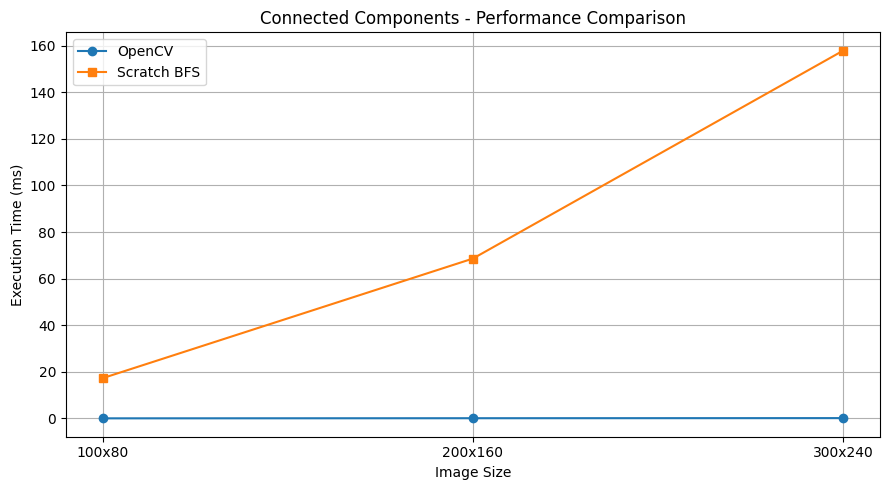

In [47]:
results_8 = [
    row for row in results
    if row["connectivity"] == 8
]

sizes = [row["size"] for row in results_8]

opencv_times = [
    row["opencv_ms"] for row in results_8
]

scratch_times = [
    row["scratch_ms"] for row in results_8
]

plt.figure(figsize=(9, 5))

plt.plot(
    sizes,
    opencv_times,
    marker="o",
    label="OpenCV"
)

plt.plot(
    sizes,
    scratch_times,
    marker="s",
    label="Scratch BFS"
)

plt.xlabel("Image Size")
plt.ylabel("Execution Time (ms)")
plt.title("Connected Components - Performance Comparison")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 17. Trực quan hóa thời gian thực thi của hai thuật toán

**Mục đích:** Biểu diễn thời gian xử lý của OpenCV và Scratch BFS trên cùng biểu đồ để đánh giá hiệu năng khi kích thước ảnh tăng.

Biểu đồ sử dụng kết quả thực nghiệm ở Cell 16 với Connectivity 8.

**Liên hệ Project:** Kết quả giúp giải thích lý do lựa chọn OpenCV làm thuật toán mặc định trong GUI. Thuật toán Scratch có thể được sử dụng làm chế độ so sánh hoặc minh họa.

Thời gian xử lý cũng là một yếu tố quan trọng khi ứng dụng cần cập nhật kết quả sau mỗi lần người dùng thay đổi tham số.